In [8]:
!pip install finance-datareader

In [9]:
import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [10]:
# 데이터 불러오기
samsung = fdr.DataReader('005930', '2016' )
print(samsung)

              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  195400  183800  187000  19855892 -0.033592
2026-11-10  199400  201500  196400  198700  14607759  0.062567

[2661 rows x 6 columns]


In [11]:
openValues = samsung[['Open']]

In [12]:
split = int(len(openValues) * 0.8)

train_data = openValues[:split]
test_data  = openValues[split-30:]
# Test 데이터는 윈도우 크기(30)만큼의 과거 데이터가 필요하므로 split - 30부터 가져온다

In [13]:
# 정규화
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range = (0, 1))
train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

In [14]:
# 순차 훈련 데이터 생성
def make_sample(data, window):
  train = []
  target = []
  for i in range(len(data)-window):
    train.append(data[i:i+window])
    target.append(data[i+window])
  return np.array(train), np.array(target)

In [15]:
WINDOW_SIZE = 30
X_train, y_train = make_sample(train_scaled, WINDOW_SIZE)
X_test, y_test = make_sample(test_scaled, WINDOW_SIZE)

In [16]:
# LSTM 구축
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM

model = Sequential()
model.add(LSTM(16, input_shape=(X_train.shape[1], 1), activation='tanh', return_sequences=False))
model.add(Dense(1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [17]:
# 모델 학습
model.compile(optimizer = 'adam', loss = 'mean_squared_error')
model.fit(X_train, y_train, epochs = 100, batch_size = 16)

Epoch 1/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.1356
Epoch 2/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0020
Epoch 3/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0013
Epoch 4/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0013
Epoch 5/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0012
Epoch 6/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0012
Epoch 7/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0012
Epoch 8/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0012
Epoch 9/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0012
Epoch 10/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0011    
Epoch 11/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0011    
Epoch 12/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0010
Epoch 13/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0010
Epoch 14/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 9.9456e-04
Epoch 15/100
132/132 ━━━━━━━━━━

In [18]:
# 주가 예측
pred = model.predict(X_test)

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


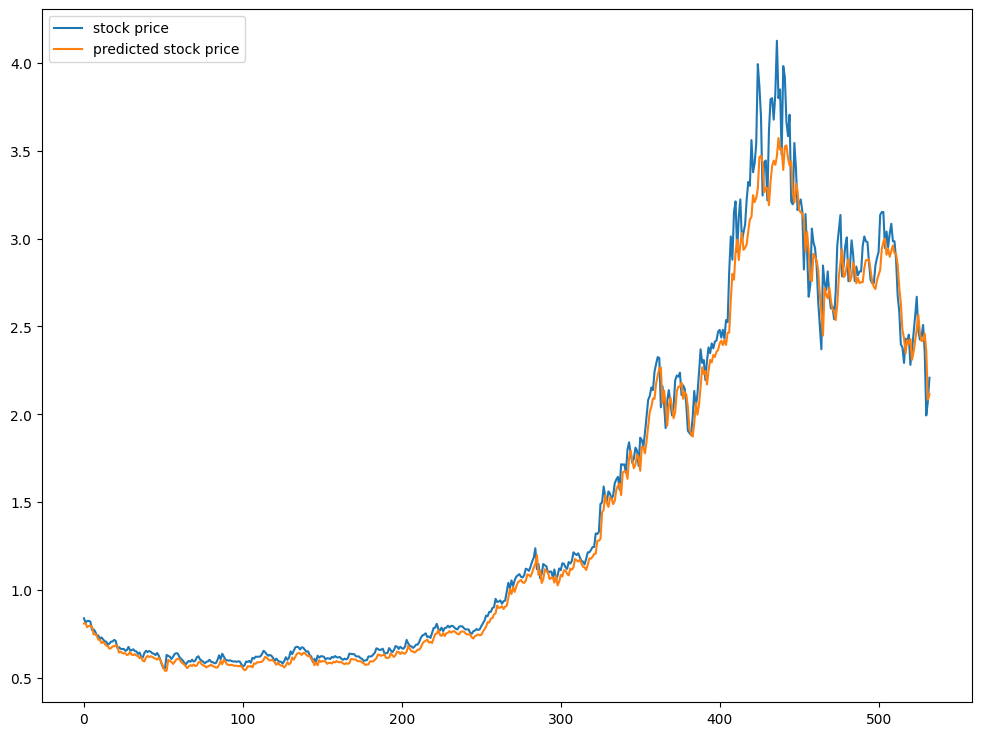

In [19]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 9))
plt.plot(y_test, label='stock price')
plt.plot(pred, label='predicted stock price')
plt.legend()
plt.show()
# 예측이 정확한 것처럼 보이지만, 사실은 1일 전의 주가를 거의 그대로 따라 읊고 있는 상태

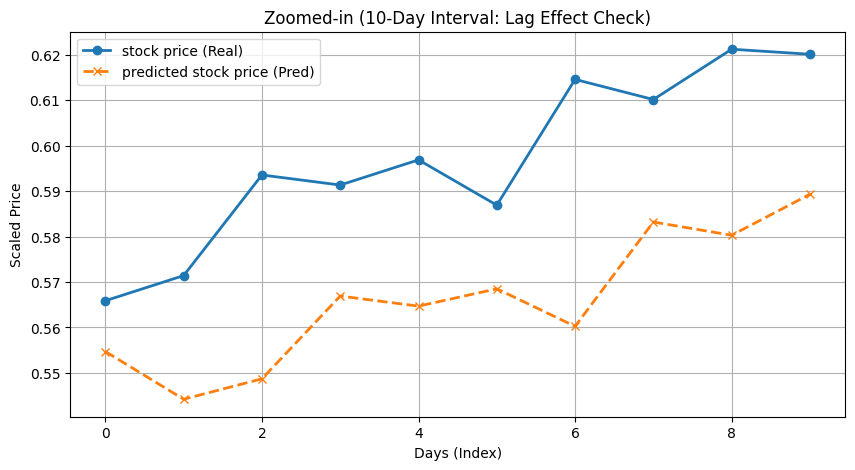

In [22]:
plt.figure(figsize=(10, 5))
plt.plot(y_test[100:110], label='stock price (Real)', marker='o', linewidth=2)
plt.plot(pred[100:110], label='predicted stock price (Pred)', marker='x', linestyle='--', linewidth=2)
plt.xlabel('Days (Index)')
plt.ylabel('Scaled Price')
plt.title("Zoomed-in (10-Day Interval: Lag Effect Check)")
plt.legend()
plt.grid(True)
plt.show()
# 10일치로 확대해서 보면 1일 전의 주가를 따라 읊고 있는 모습을 볼 수 있다